# Assignment UT3-10: PCA y Feature Selection

**Nombre:** Marcos Devincenzi  

## Objetivos y contexto

Predecir `SalePrice` en Ames Housing; analizar PCA, comparar filtros, wrappers y métodos embedded; evaluar el equilibrio entre precisión, costo e interpretabilidad para una inmobiliaria.

**Datos:** se usa el `train.csv` de Kaggle, con 1460 filas, 81 columnas, 79 predictores al excluir `Id` y `SalePrice`. No se confunden las 1460 casas con las aproximadamente 2900 del conjunto completo de Ames.

**Correcciones de la consigna:** `SalePrice` requiere regresores y métricas RMSE/R², también en los bloques opcionales. El consenso se calcula sobre el número real de métodos. Los subconjuntos conservan el mismo orden de columnas que sus nombres. Los tamaños de cada wrapper se informan realmente, en lugar de presentar todos como si tuvieran k variables.

**Evaluación:** se reserva 20 % de las casas como prueba. La CV de los subconjuntos ya seleccionados es exploratoria y puede ser optimista: condiciona la evaluación a una selección realizada con todo el desarrollo. Se incluye una auditoría con selección dentro de cada fold para métodos rápidos y una única evaluación final de prueba después de fijar el método. Los tiempos son mediciones de este equipo, no promesas de rendimiento.


## Parte 1: Setup Rápido - Dataset Ames Housing

### Paso 1.1: Setup Rápido - Cargar y Preprocesar

In [1]:
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from joblib import parallel_backend
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, KFold, cross_validate, cross_val_score
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, PolynomialFeatures, KBinsDiscretizer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import PCA, IncrementalPCA
from sklearn.feature_selection import SelectKBest, f_regression, mutual_info_regression, chi2, RFE, SequentialFeatureSelector
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score

SEMILLA = 42
N_JOBS = 4
np.random.seed(SEMILLA)
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
CACHE = Path('pca_resultados/cache')
CACHE.mkdir(parents=True, exist_ok=True)
rutas = [Path('data/ames_train.csv'), Path('train.csv'), Path('../data/ames_train.csv')]
DATA_PATH = next((p for p in rutas if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Colocar ames_train.csv en data/ o train.csv junto al notebook.')
df = pd.read_csv(DATA_PATH)
assert df.shape == (1460, 81) and 'SalePrice' in df
X_raw = df.drop(columns=['Id', 'SalePrice'])
y_total = df.SalePrice
X_dev_raw, X_test_raw, y, y_test = train_test_split(
    X_raw, y_total, test_size=0.2, random_state=SEMILLA)
num_cols = X_raw.select_dtypes(include='number').columns.tolist()
cat_cols = X_raw.select_dtypes(exclude='number').columns.tolist()

def make_preprocessor():
    return ColumnTransformer([
        ('num', SimpleImputer(strategy='median', keep_empty_features=True), num_cols),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent', keep_empty_features=True),
                             OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)), cat_cols)
    ], verbose_feature_names_out=False)

# OrdinalEncoder reproduce la codificación alfabética usada con LabelEncoder,
# pero puede aplicar el mapeo aprendido a categorías nuevas sin volver a ajustarlo.
preprocessor = make_preprocessor()
X = pd.DataFrame(preprocessor.fit_transform(X_dev_raw),
                 columns=preprocessor.get_feature_names_out(), index=X_dev_raw.index)
feature_names = X.columns.tolist()
print('Dataset:', df.shape, '| predictores:', X.shape[1])
print('Numéricas:', len(num_cols), '| categóricas:', len(cat_cols))
print('Desarrollo:', len(y), '| prueba reservada:', len(y_test))
print('Precio medio: $', round(y_total.mean()), '| mediana: $', round(y_total.median()))
print('Nulos antes:', int(X_dev_raw.isna().sum().sum()), '| después:', int(X.isna().sum().sum()))
X.head()

Dataset: (1460, 81) | predictores: 79
Numéricas: 36 | categóricas: 43
Desarrollo: 1168 | prueba reservada: 292
Precio medio: $ 180921 | mediana: $ 163000
Nulos antes: 6227 | después: 0


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,TotRmsAbvGrd,Fireplaces,GarageYrBlt,GarageCars,GarageArea,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,Heating,HeatingQC,CentralAir,Electrical,KitchenQual,Functional,FireplaceQu,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
254,20.0,70.0,8400.0,5.0,6.0,1957.0,1957.0,0.0,922.0,0.0,392.0,1314.0,1314.0,0.0,0.0,1314.0,1.0,0.0,1.0,0.0,3.0,1.0,5.0,0.0,1957.0,1.0,294.0,250.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,2010.0,3.0,1.0,0.0,3.0,3.0,0.0,4.0,0.0,12.0,2.0,2.0,0.0,2.0,1.0,1.0,8.0,8.0,1.0,3.0,2.0,1.0,3.0,3.0,3.0,4.0,5.0,1.0,4.0,1.0,3.0,3.0,6.0,2.0,1.0,1.0,4.0,4.0,2.0,0.0,2.0,2.0,8.0,4.0
1066,60.0,59.0,7837.0,6.0,7.0,1993.0,1994.0,0.0,0.0,0.0,799.0,799.0,799.0,772.0,0.0,1571.0,0.0,0.0,2.0,1.0,3.0,1.0,7.0,1.0,1993.0,2.0,380.0,0.0,40.0,0.0,0.0,0.0,0.0,0.0,5.0,2009.0,3.0,1.0,0.0,0.0,3.0,0.0,4.0,0.0,8.0,2.0,2.0,0.0,5.0,1.0,1.0,12.0,13.0,1.0,2.0,4.0,2.0,2.0,3.0,3.0,5.0,5.0,1.0,2.0,1.0,3.0,3.0,6.0,4.0,1.0,1.0,4.0,4.0,2.0,0.0,2.0,2.0,8.0,4.0
638,30.0,67.0,8777.0,5.0,7.0,1910.0,1950.0,0.0,0.0,0.0,796.0,796.0,796.0,0.0,0.0,796.0,0.0,0.0,1.0,0.0,2.0,1.0,4.0,0.0,1980.0,0.0,0.0,328.0,0.0,164.0,0.0,0.0,0.0,0.0,5.0,2008.0,3.0,1.0,0.0,3.0,3.0,0.0,4.0,0.0,7.0,1.0,2.0,0.0,2.0,1.0,1.0,8.0,14.0,1.0,3.0,4.0,1.0,1.0,3.0,3.0,5.0,5.0,1.0,2.0,1.0,0.0,3.0,6.0,2.0,1.0,2.0,4.0,4.0,1.0,0.0,2.0,2.0,8.0,4.0
799,50.0,60.0,7200.0,5.0,7.0,1937.0,1950.0,252.0,569.0,0.0,162.0,731.0,981.0,787.0,0.0,1768.0,1.0,0.0,1.0,1.0,3.0,1.0,7.0,2.0,1939.0,1.0,240.0,0.0,0.0,264.0,0.0,0.0,0.0,0.0,6.0,2007.0,3.0,1.0,0.0,3.0,3.0,0.0,0.0,0.0,18.0,1.0,2.0,0.0,0.0,1.0,1.0,13.0,14.0,1.0,3.0,4.0,0.0,2.0,3.0,3.0,0.0,5.0,1.0,0.0,1.0,3.0,2.0,6.0,4.0,5.0,2.0,4.0,4.0,2.0,0.0,2.0,2.0,8.0,4.0
380,50.0,50.0,5000.0,5.0,6.0,1924.0,1950.0,0.0,218.0,0.0,808.0,1026.0,1026.0,665.0,0.0,1691.0,0.0,0.0,2.0,0.0,3.0,1.0,6.0,1.0,1924.0,1.0,308.0,0.0,0.0,242.0,0.0,0.0,0.0,0.0,5.0,2010.0,3.0,1.0,1.0,3.0,3.0,0.0,4.0,0.0,18.0,2.0,2.0,0.0,0.0,1.0,1.0,3.0,14.0,1.0,3.0,4.0,0.0,3.0,3.0,3.0,3.0,5.0,1.0,4.0,1.0,3.0,2.0,6.0,2.0,5.0,2.0,4.0,4.0,2.0,0.0,2.0,2.0,8.0,4.0


### Pregunta Reflexiva 1 — Respuesta

No todas las variables aportan lo mismo. Tamaño, calidad y ubicación pueden ser relevantes; otras variables aportan poca señal, se solapan o corresponden a situaciones muy raras. Demasiadas variables pueden aumentar el costo, la inestabilidad y el sobreajuste, además de dificultar la explicación. PCA transforma las variables en combinaciones lineales; feature selection conserva un subconjunto de las variables originales.

La codificación alfabética es fiel al enfoque simplificado de la actividad, pero impone distancias arbitrarias entre categorías nominales. Para producción compararía también One-Hot Encoding y codificación ordinal definida por conocimiento del dominio.

## Parte 2: PCA - Análisis de Componentes Principales

### Paso 2.1: Estandarización

In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Shape:', X_scaled.shape)
print('Máxima media absoluta por columna:', np.max(np.abs(X_scaled.mean(axis=0))))
print('Desvíos por columna:', np.unique(np.round(X_scaled.std(axis=0), 6)))
print('GrLivArea antes:', X.GrLivArea.mean(), X.GrLivArea.std(ddof=0))
print('GrLivArea después:', X_scaled[:, X.columns.get_loc('GrLivArea')].mean(),
      X_scaled[:, X.columns.get_loc('GrLivArea')].std())

Shape: (1168, 79)
Máxima media absoluta por columna: 6.596853961115177e-14
Desvíos por columna: [1.]
GrLivArea antes: 1527.4015410958905 524.2081378733961
GrLivArea después: -1.307933974215938e-16 1.0


### Pregunta Reflexiva 2 — Respuesta

PCA maximiza varianza: sin estandarizar, una variable medida en una escala grande puede dominar aunque no sea más informativa. `LotArea`, `GrLivArea` y las superficies del sótano competirían con mucho más peso que atributos codificados de 0 a pocos enteros. Estandarizar pone las variables no constantes en una escala comparable. No es una exigencia matemática universal: si las variables comparten unidades y sus diferencias de varianza tienen significado —por ejemplo, señales de sensores calibrados de la misma magnitud— puede interesar PCA sobre la covarianza sin normalizar.

### Paso 2.2: Aplicar PCA Completo

In [3]:
inicio = time.perf_counter()
pca = PCA(svd_solver='full').fit(X_scaled)
X_pca = pca.transform(X_scaled)
tiempo_pca = time.perf_counter() - inicio
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
def componentes_para(umbral):
    return int(np.searchsorted(cumulative_variance, umbral) + 1)
print('Componentes:', pca.n_components_, '| tiempo:', tiempo_pca)
pd.DataFrame({'PC': np.arange(1, 11), 'varianza': explained_variance[:10],
              'acumulada': cumulative_variance[:10]})

Componentes: 79 | tiempo: 0.015567900001769885


,PC,varianza,acumulada
0,1,0.130959,0.130959
1,2,0.052262,0.183222
2,3,0.049560,0.232782
3,4,0.037337,0.270119
4,5,0.030402,0.300521
5,6,0.027231,0.327752
6,7,0.025586,0.353338
7,8,0.023724,0.377062
8,9,0.022669,0.399731
9,10,0.021549,0.421280


### Pregunta Reflexiva 3 — Respuesta

PC1 explica 13.10% y hacen falta 15 componentes para llegar a 50 %. No existe un porcentaje «típico» universal con el que afirmar que PC1 es excepcional. Las superficies, la calidad y la antigüedad tienen relaciones entre sí, lo que concentra parte de su variación, pero hay muchas dimensiones distintas. PC1 puede describirse como un eje que resume características que varían juntas; sus loadings, calculados en el siguiente paso, permiten precisar cuáles. No es un índice directo de precio porque PCA no usa SalePrice.

### Paso 2.3: Scree Plot y Decisión de Dimensionalidad

{0.5: 15, 0.8: 38, 0.9: 50, 0.95: 59, 0.99: 71}


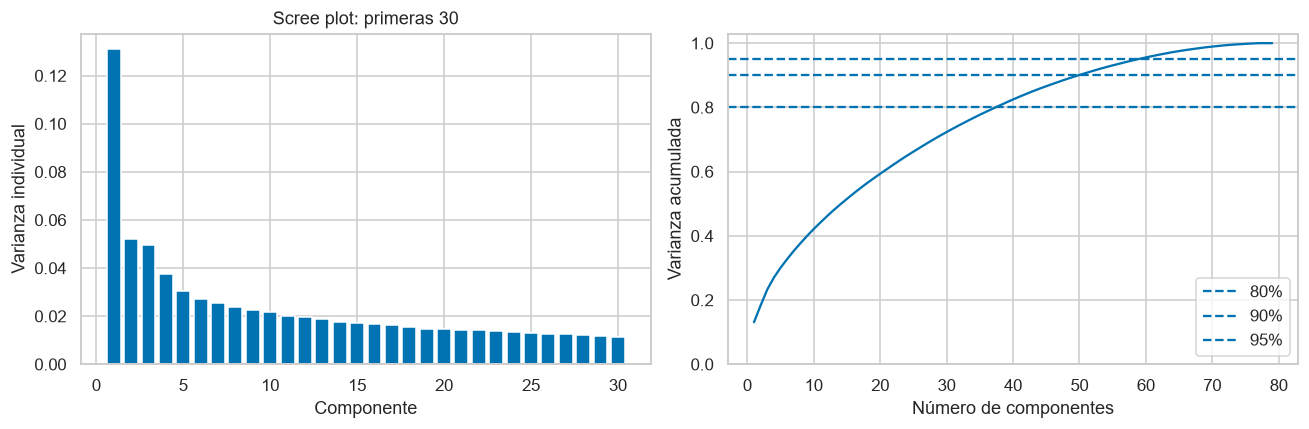

In [4]:
n_components_80 = componentes_para(0.80)
n_components_90 = componentes_para(0.90)
n_components_95 = componentes_para(0.95)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].bar(np.arange(1, 31), explained_variance[:30])
axs[0].set(xlabel='Componente', ylabel='Varianza individual', title='Scree plot: primeras 30')
axs[1].plot(np.arange(1, len(cumulative_variance)+1), cumulative_variance)
for umbral in [0.80, 0.90, 0.95]:
    axs[1].axhline(umbral, ls='--', label=f'{umbral:.0%}')
axs[1].set(xlabel='Número de componentes', ylabel='Varianza acumulada', ylim=(0, 1.03))
axs[1].legend(); plt.tight_layout(); plt.show()
print({u: componentes_para(u) for u in [0.5, 0.8, 0.9, 0.95, 0.99]})

### Pregunta Reflexiva 4 — Respuesta

Con 80 % se pasa de 79 a 38 dimensiones: reducción de 51.9 %. Con 90 % hacen falta 50 y con 95 %, 59. La reducción es apreciable, pero el porcentaje de varianza no equivale al porcentaje de información predictiva conservada. Para producción elegiría el umbral por validación del error y latencia; en tasación priorizaría evitar una pérdida importante de precisión. El trabajo domiciliario compara los umbrales antes de decidir, en lugar de asumir que 80 % es óptimo.

### Paso 2.4: Interpretación de Loadings

                   PC1       PC2
OverallQual   0.817025  0.119842
YearBuilt     0.760645  0.335273
GarageCars    0.732554  0.048822
GarageArea    0.711636  0.013089
GarageYrBlt   0.691004  0.199097
ExterQual     0.687167  0.013443
GarageFinish  0.685918  0.117489
BsmtQual      0.682543  0.044842
TotalBsmtSF   0.657144  0.176930
YearRemodAdd  0.655143  0.082068
Top PC2: ['2ndFlrSF', 'TotRmsAbvGrd', 'BedroomAbvGr', 'GrLivArea', 'BsmtFinType1']


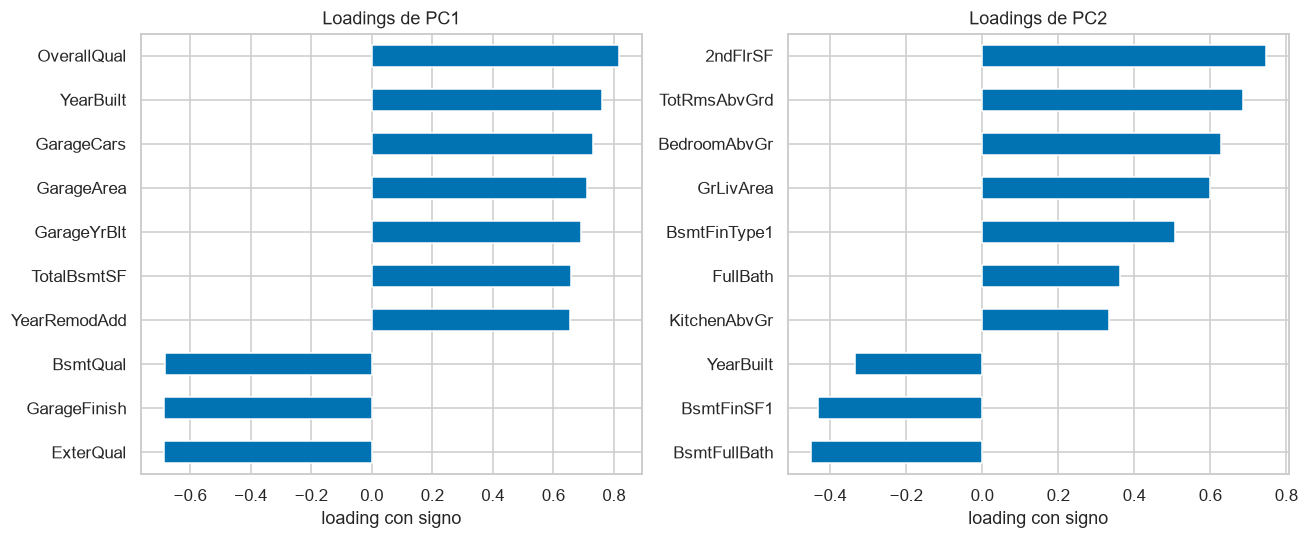

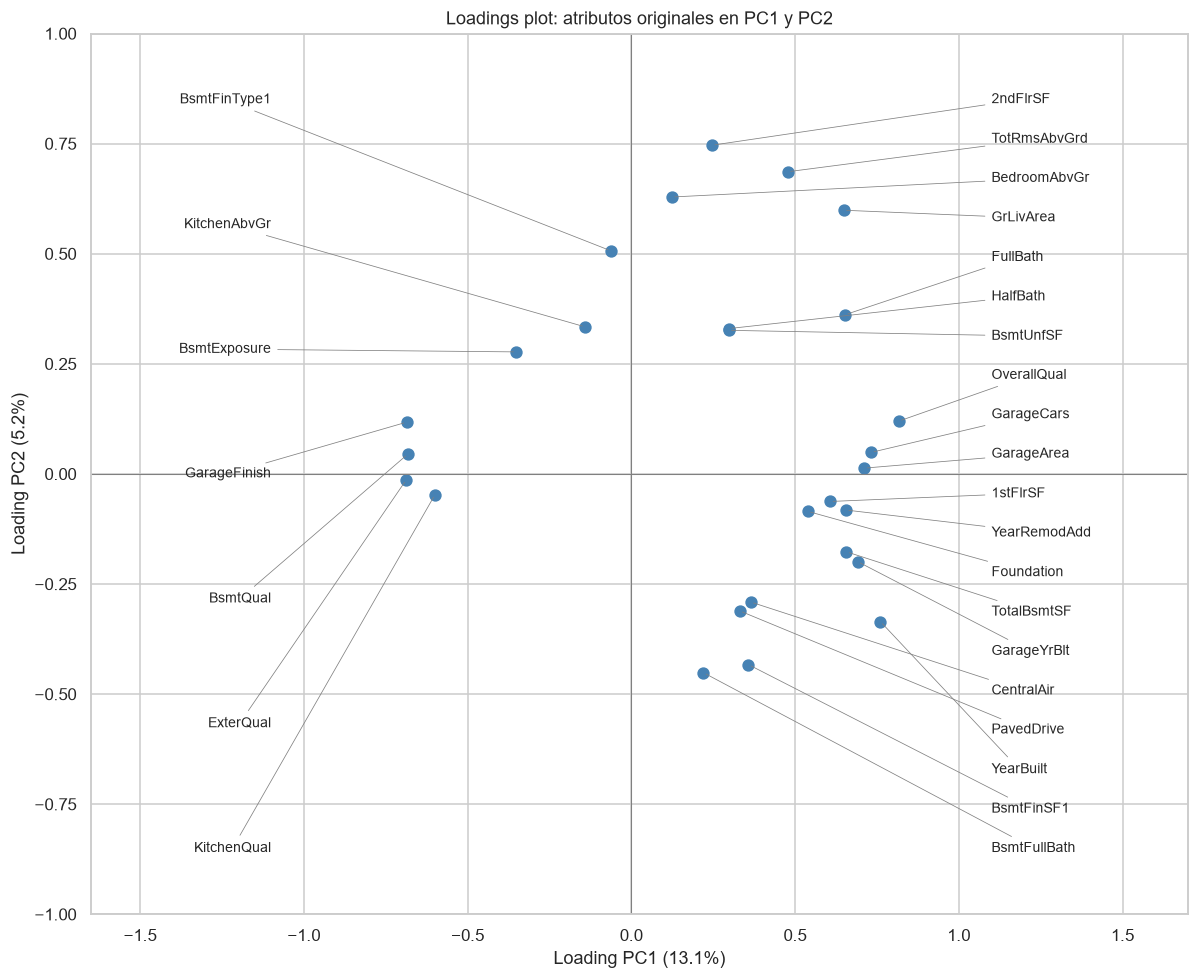

In [5]:
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
loadings_df = pd.DataFrame(loadings[:, :2], index=X.columns, columns=['PC1', 'PC2'])
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for j, ax in enumerate(axs):
    top = loadings_df.iloc[:, j].abs().nlargest(10).index
    loadings_df.loc[top].iloc[:, j].sort_values().plot.barh(ax=ax)
    ax.set_title(f'Loadings de PC{j+1}'); ax.set_xlabel('loading con signo')
plt.tight_layout(); plt.show()
print(loadings_df.abs().sort_values('PC1', ascending=False).head(10).to_string())
print('Top PC2:', loadings_df.PC2.abs().nlargest(5).index.tolist())
# Loadings plot PC1 vs PC2, unión de las 15 variables dominantes por eje.
top_features = sorted(set(loadings_df.PC1.abs().nlargest(15).index)
                      | set(loadings_df.PC2.abs().nlargest(15).index))
loadings_df_viz = loadings_df.loc[top_features]
fig, ax = plt.subplots(figsize=(11, 9))
ax.scatter(loadings_df_viz.PC1, loadings_df_viz.PC2, s=50, color='steelblue')
for lado in [-1, 1]:
    grupo = loadings_df_viz[(loadings_df_viz.PC1 >= 0) if lado == 1 else (loadings_df_viz.PC1 < 0)]
    grupo = grupo.sort_values('PC2')
    posiciones = np.linspace(-0.85, 0.85, len(grupo))
    for (nombre, fila), ypos in zip(grupo.iterrows(), posiciones):
        ax.annotate(nombre, (fila.PC1, fila.PC2), xytext=(lado*1.10, ypos),
                    ha='left' if lado==1 else 'right', va='center', fontsize=9,
                    arrowprops={'arrowstyle':'-', 'color':'gray', 'lw':0.5})
ax.axhline(0, color='gray', lw=0.7); ax.axvline(0, color='gray', lw=0.7)
ax.set(xlabel=f'Loading PC1 ({explained_variance[0]:.1%})',
       ylabel=f'Loading PC2 ({explained_variance[1]:.1%})',
       xlim=(-1.65,1.70), ylim=(-1,1), title='Loadings plot: atributos originales en PC1 y PC2')
plt.tight_layout(); plt.show()


### Pregunta Reflexiva 5 — Respuesta

En PC1 dominan OverallQual, YearBuilt, GarageCars, GarageArea, GarageYrBlt. En PC2 dominan 2ndFlrSF, TotRmsAbvGrd, BedroomAbvGr, GrLivArea, BsmtFinType1. Son dimensiones de la vivienda que pueden relacionarse con su precio, pero aquí se interpreta variación de X, no causalidad ni una importancia supervisada. Los componentes son transparentes en términos matemáticos —cada peso se conoce—, aunque difíciles de explicar como atributos individuales. A un agente describiría PC1 con esas características que se mueven conjuntamente, sin decir que una unidad de PC1 sea un aumento fijo del precio. El signo de un componente se puede invertir sin cambiar el PCA.

### Paso 2.5: Feature Selection Basada en PCA Loadings

k: 38 | features por loadings: ['Fence', 'Functional', 'LowQualFinSF', 'Condition2', 'Heating', 'BsmtCond', 'YrSold', '3SsnPorch', 'LotConfig', 'LotShape', 'Utilities', 'Neighborhood', 'ScreenPorch', 'Street', 'ExterCond', 'RoofStyle', 'LandContour', 'RoofMatl', 'BsmtHalfBath', 'EnclosedPorch', 'Alley', 'Condition1', 'MoSold', 'FireplaceQu', 'SaleType', 'OpenPorchSF', 'SaleCondition', 'WoodDeckSF', 'GarageCond', 'OverallCond', 'Electrical', 'BsmtExposure', 'KitchenAbvGr', 'GarageQual', 'PoolQC', 'GarageType', 'MasVnrType', 'MasVnrArea']


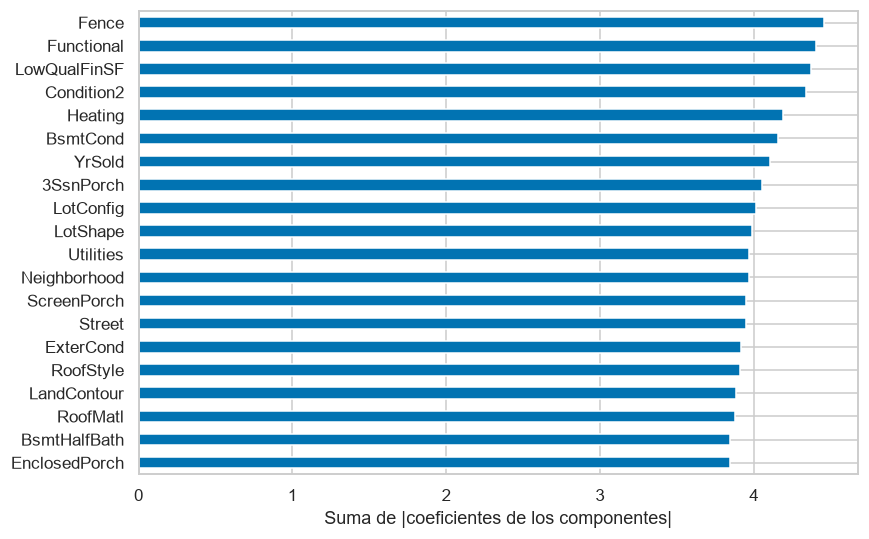

In [6]:
n_top_components = n_components_80
loadings_all = pd.DataFrame(pca.components_[:n_top_components].T, index=X.columns)
feature_importance_from_pca = loadings_all.abs().sum(axis=1).sort_values(ascending=False)
k = n_components_80
selected_features_pca = feature_importance_from_pca.nlargest(k).index.tolist()
idx_pca = X.columns.get_indexer(selected_features_pca)
X_pca_selected = X_scaled[:, idx_pca]
print('k:', k, '| features por loadings:', selected_features_pca)
feature_importance_from_pca.head(20).sort_values().plot.barh(figsize=(8, 5))
plt.xlabel('Suma de |coeficientes de los componentes|'); plt.tight_layout(); plt.show()

### Pregunta Reflexiva 5.5 — Respuesta

La selección por loadings conserva nombres de variables, mientras PCA usa nuevos ejes. Algunos atributos seleccionados tienen sentido de negocio y otros pueden sorprender, porque este ranking favorece participación en la variación de X, no asociación con el precio. Además, sumar pesos absolutos sin ponderarlos por varianza es una heurística, no una medida universal de relevancia. Para una inmobiliaria preferiría variables originales si mantienen el error: facilitan capturar, verificar y explicar los datos. Seleccionar por loadings no garantiza ser mejor que un filtro supervisado.

El resultado confirma esa limitación: seleccionar por suma de loadings dejó fuera `OverallQual` y `GrLivArea` y obtuvo RMSE exploratorio de $50,126, frente a $29,931 usando todas las variables. Los wrappers que parten de esa preselección no pueden recuperar atributos ya descartados; el trabajo domiciliario 3 empieza por las 79 variables y permite contrastarlo.

### Paso 2.6: Evaluación de Performance con REGRESIÓN (RMSE y R²)

In [7]:
CV5 = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
CV3 = KFold(n_splits=3, shuffle=True, random_state=SEMILLA)
def bosque(n=100, profundidad=15):
    return RandomForestRegressor(n_estimators=n, max_depth=profundidad,
                                 random_state=SEMILLA, n_jobs=1)
def evaluar_matriz(nombre, Z):
    with parallel_backend('threading'):
        r = cross_validate(bosque(), Z, y, cv=CV5,
                           scoring={'rmse':'neg_root_mean_squared_error', 'r2':'r2'}, n_jobs=N_JOBS)
    return {'Método':nombre, 'N_Features':Z.shape[1], 'RMSE':-r['test_rmse'].mean(),
            'RMSE_std':r['test_rmse'].std(), 'R2':r['test_r2'].mean(),
            'fit_s':r['fit_time'].mean()}
def evaluar_pca(umbral):
    pipe = make_pipeline(make_preprocessor(), StandardScaler(), PCA(n_components=umbral, svd_solver='full'), bosque())
    with parallel_backend('threading'):
        r = cross_validate(pipe, X_dev_raw, y, cv=CV5,
                           scoring={'rmse':'neg_root_mean_squared_error','r2':'r2'}, n_jobs=N_JOBS)
    return {'Método':f'PCA {umbral:.0%}', 'N_Features':componentes_para(umbral),
            'RMSE':-r['test_rmse'].mean(), 'RMSE_std':r['test_rmse'].std(),
            'R2':r['test_r2'].mean(), 'fit_s':r['fit_time'].mean()}
evaluaciones = [evaluar_matriz('Original', X_scaled), evaluar_pca(0.80),
                evaluar_matriz('PCA Loadings', X_pca_selected)]
matrices = {'Original': X_scaled, 'PCA Loadings':X_pca_selected}
conjuntos = {'Original':feature_names, 'PCA Loadings':selected_features_pca}
tiempos_seleccion = {'PCA Loadings':tiempo_pca}
pd.DataFrame(evaluaciones)

,Método,N_Features,RMSE,RMSE_std,R2,fit_s
0,Original,79,29930.880476,4497.706506,0.847647,0.712511
1,PCA 80%,38,31179.042836,3053.818354,0.836279,0.975310
2,PCA Loadings,38,50126.073898,4165.129384,0.576643,0.291164


### Pregunta Reflexiva 6 — Respuesta

El original tiene RMSE de $29,931 y R²=0.848. PCA 80 % tiene RMSE $31,179 y R²=0.836: diferencia de $1,248. Reducir 51.9 % de dimensiones no garantiza conservar la señal del precio. Un bosque produce cortes por ejes; rotar esos ejes puede hacerlo menos eficiente aun conservando mucha varianza. Para una aplicación con fuerte restricción de almacenamiento o atributos correlacionados podría preferirse PCA, pero en tasación justificaría la pérdida de precisión explícitamente. El costo incluye escalar y proyectar cada casa, además de predecir: no se debe inferir velocidad solo contando columnas. La CV de PCA se calculó ajustando todo su pipeline en cada fold; la de las variables ya seleccionadas es exploratoria.

## Parte 3: Feature Selection - Filter Methods

### Paso 3.1: Filter Method - F-test

Features: ['LotFrontage', 'LotArea', 'OverallQual', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'BsmtFullBath', 'FullBath', 'HalfBath', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'MSZoning', 'LotShape', 'Neighborhood', 'RoofStyle', 'MasVnrType', 'ExterQual', 'Foundation', 'BsmtQual', 'BsmtExposure', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'GarageType', 'GarageFinish', 'PavedDrive']


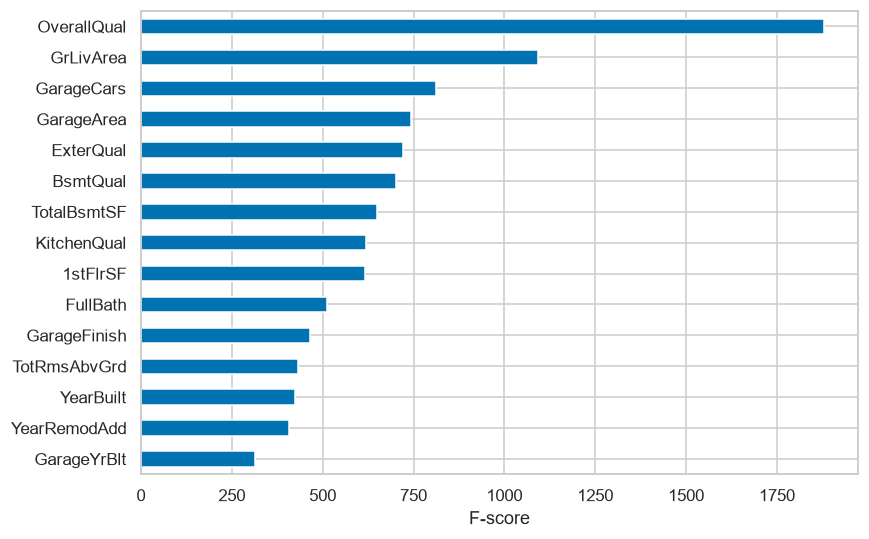

In [8]:
inicio = time.perf_counter()
selector_f = SelectKBest(f_regression, k=k).fit(X_scaled, y)
f_scores = pd.Series(selector_f.scores_, index=X.columns).sort_values(ascending=False)
selected_features_f = X.columns[selector_f.get_support()].tolist()
X_filter_f = selector_f.transform(X_scaled)
tiempos_seleccion['F-test'] = time.perf_counter() - inicio
conjuntos['F-test'], matrices['F-test'] = selected_features_f, X_filter_f
print('Features:', selected_features_f)
f_scores.head(15).sort_values().plot.barh(figsize=(8, 5)); plt.xlabel('F-score'); plt.tight_layout(); plt.show()

### Pregunta Reflexiva 7 — Respuesta

Los cinco primeros son OverallQual, GrLivArea, GarageCars, GarageArea, ExterQual: representan características relacionadas con calidad, tamaño o equipamiento, por lo que su relevancia para tasar resulta razonable. No asumiría que todos los primeros puestos fueran previsibles: datos raros y la codificación pueden afectar el ranking. `f_regression` mide asociación lineal univariada; no captura por sí solo interacciones ni todas las relaciones no lineales. Atributos correlacionados pueden aparecer juntos y aportar información redundante.

### Paso 3.2: Filter Method - Mutual Information

Top MI: OverallQual     0.540663
Neighborhood    0.493049
GrLivArea       0.456919
GarageArea      0.363094
GarageCars      0.349285
TotalBsmtSF     0.345863
YearBuilt       0.333302
BsmtQual        0.308362
KitchenQual     0.306814
ExterQual       0.304582
1stFlrSF        0.298221
MSSubClass      0.297287
GarageYrBlt     0.276145
FullBath        0.257155
GarageFinish    0.241938
Solo en MI: ['BsmtFinType1', 'Exterior1st', 'Exterior2nd', 'FireplaceQu', 'HouseStyle', 'MSSubClass', 'OverallCond']


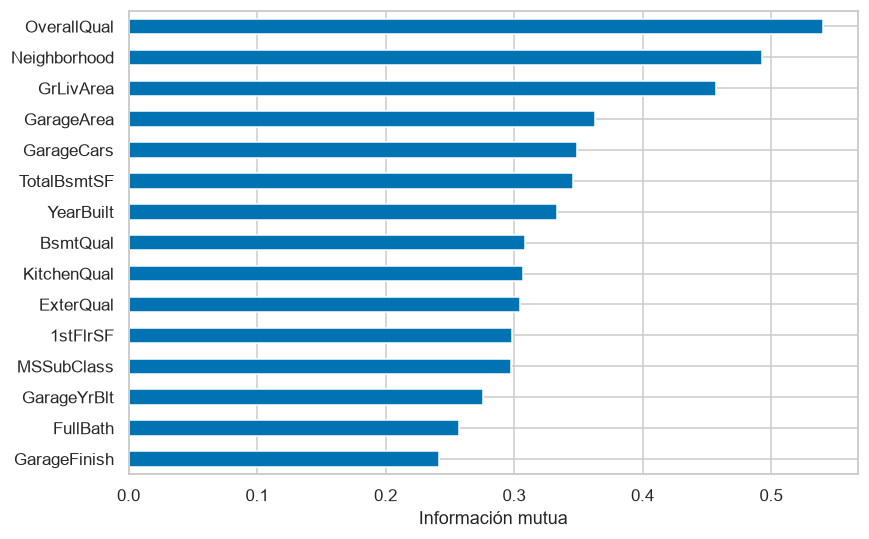

In [9]:
inicio = time.perf_counter()
discretas = np.array([c in cat_cols or X[c].nunique() < 20 for c in X.columns])
mi_scores = pd.Series(mutual_info_regression(X_scaled, y, discrete_features=discretas,
                                             random_state=SEMILLA), index=X.columns).sort_values(ascending=False)
selected_features_mi = mi_scores.nlargest(k).index.tolist()
X_filter_mi = X_scaled[:, X.columns.get_indexer(selected_features_mi)]
tiempos_seleccion['MI'] = time.perf_counter() - inicio
conjuntos['MI'], matrices['MI'] = selected_features_mi, X_filter_mi
solo_mi = sorted(set(selected_features_mi)-set(selected_features_f))
print('Top MI:', mi_scores.head(15).to_string())
print('Solo en MI:', solo_mi)
mi_scores.head(15).sort_values().plot.barh(figsize=(8, 5)); plt.xlabel('Información mutua'); plt.tight_layout(); plt.show()

### Pregunta Reflexiva 8 — Respuesta

Solo MI selecciona BsmtFinType1, Exterior1st, Exterior2nd, FireplaceQu, HouseStyle, MSSubClass, OverallCond. Puede detectar dependencias no lineales y diferencias entre grupos que un F-score lineal no resume; también tiene ruido de estimación. En variables de barrio o calidad es plausible una relación por niveles y no una recta; el ranking por sí solo no demuestra esa forma y habría que verla con gráficos. Para un bosque usaría MI como candidato útil, y F-test como referencia rápida; escogería por validación y estabilidad, no por el nombre del método.

### Paso 3.3: Evaluar Performance de Filter Methods

In [10]:
evaluaciones += [evaluar_matriz('F-test', X_filter_f), evaluar_matriz('MI', X_filter_mi)]
comparacion_filter = pd.DataFrame(evaluaciones).sort_values('RMSE')
comparacion_filter

,Método,N_Features,RMSE,RMSE_std,R2,fit_s
4,MI,38,29839.934575,4485.556178,0.848327,0.517665
0,Original,79,29930.880476,4497.706506,0.847647,0.712511
3,F-test,38,30387.227780,4627.280747,0.842418,0.498289
1,PCA 80%,38,31179.042836,3053.818354,0.836279,0.975310
2,PCA Loadings,38,50126.073898,4165.129384,0.576643,0.291164


### Pregunta Reflexiva 9 — Respuesta

En la comparación hasta este punto gana MI con RMSE $29,840. Las variables originales permiten al bosque usar señales específicas y conservar una explicación en atributos de las casas; PCA solo prioriza varianza y puede diluir esa señal. Compararía la diferencia con la variabilidad entre folds antes de concluir que un método es superior. Para el equipo inmobiliario favorecería una selección interpretable cuando el error es comparable. Las filas con selección previa son diagnósticas y deben confirmarse con evaluación independiente.

## Parte 4: Feature Selection - Wrapper Methods

### Paso 4.1: Forward Selection (Sequential Feature Selection)

In [11]:
k_wrapper = min(len(selected_features_pca)-1, max(15, k//2))
def ejecutar_wrapper(direccion, Z, nombres, n_seleccionar, etiqueta):
    cache = CACHE / f'{etiqueta}.joblib'
    if cache.exists():
        selector, segundos = joblib.load(cache)
        print('Resultado guardado reutilizado:', etiqueta, '| tiempo original:', segundos)
    else:
        selector = SequentialFeatureSelector(bosque(50, 10), n_features_to_select=n_seleccionar,
                                             direction=direccion, cv=CV3,
                                             scoring='neg_root_mean_squared_error', n_jobs=N_JOBS)
        inicio = time.perf_counter()
        with parallel_backend('threading'):
            selector.fit(Z, y)
        segundos = time.perf_counter()-inicio
        joblib.dump((selector, segundos), cache)
    seleccion = np.array(nombres)[selector.get_support()].tolist()
    return selector, seleccion, selector.transform(Z), segundos
selector_forward, selected_features_forward, X_forward, tiempo_forward = ejecutar_wrapper(
    'forward', X_pca_selected, selected_features_pca, k_wrapper, 'main_forward')
conjuntos['Forward'], matrices['Forward'] = selected_features_forward, X_forward
tiempos_seleccion['Forward'] = tiempo_forward
print('Preselección:', k, '->', len(selected_features_forward), '| segundos:', tiempo_forward)
print(selected_features_forward)

Preselección: 38 -> 19 | segundos: 53.842789099988295
['Functional', 'Condition2', 'Heating', '3SsnPorch', 'LotShape', 'Neighborhood', 'ScreenPorch', 'RoofStyle', 'RoofMatl', 'Alley', 'Condition1', 'FireplaceQu', 'OpenPorchSF', 'SaleCondition', 'GarageCond', 'Electrical', 'KitchenAbvGr', 'PoolQC', 'GarageType']


### Paso 4.2: Backward Elimination (Sequential Feature Selection)

In [12]:
selector_backward, selected_features_backward, X_backward, tiempo_backward = ejecutar_wrapper(
    'backward', X_pca_selected, selected_features_pca, k_wrapper, 'main_backward')
conjuntos['Backward'], matrices['Backward'] = selected_features_backward, X_backward
tiempos_seleccion['Backward'] = tiempo_backward
print('Preselección:', k, '->', len(selected_features_backward), '| segundos:', tiempo_backward)
print(selected_features_backward)
print('Comunes:', sorted(set(selected_features_forward) & set(selected_features_backward)))

Preselección: 38 -> 19 | segundos: 70.77119140001014
['LowQualFinSF', 'Condition2', 'BsmtCond', 'YrSold', 'LotShape', 'Neighborhood', 'ScreenPorch', 'RoofStyle', 'Alley', 'Condition1', 'FireplaceQu', 'OpenPorchSF', 'SaleCondition', 'OverallCond', 'Electrical', 'KitchenAbvGr', 'PoolQC', 'GarageType', 'MasVnrType']
Comunes: ['Alley', 'Condition1', 'Condition2', 'Electrical', 'FireplaceQu', 'GarageType', 'KitchenAbvGr', 'LotShape', 'Neighborhood', 'OpenPorchSF', 'PoolQC', 'RoofStyle', 'SaleCondition', 'ScreenPorch']


### Pregunta Reflexiva — Forward vs Backward: Respuesta

Forward tardó 53.8 s y backward 70.8 s. Forward agrega atributos y comienza con modelos pequeños; backward comienza con todos los candidatos y elimina uno por paso. La cantidad de candidatos evaluados y el tamaño de cada modelo explican el costo. Coinciden en 14 de 19 atributos. Son búsquedas greedy: dependen del recorrido y de qué variables ya están presentes. Preferiría forward para un conjunto final pequeño y backward cuando interesa conservar una gran parte o evaluar aportes condicionados a muchas variables.

### Paso 4.3: Recursive Feature Elimination (RFE)

Tiempo: 1.2874903999909293 | features: ['YrSold', 'LotConfig', 'LotShape', 'Neighborhood', 'ScreenPorch', 'RoofStyle', 'LandContour', 'RoofMatl', 'EnclosedPorch', 'MoSold', 'FireplaceQu', 'OpenPorchSF', 'SaleCondition', 'WoodDeckSF', 'OverallCond', 'BsmtExposure', 'GarageType', 'MasVnrType', 'MasVnrArea']


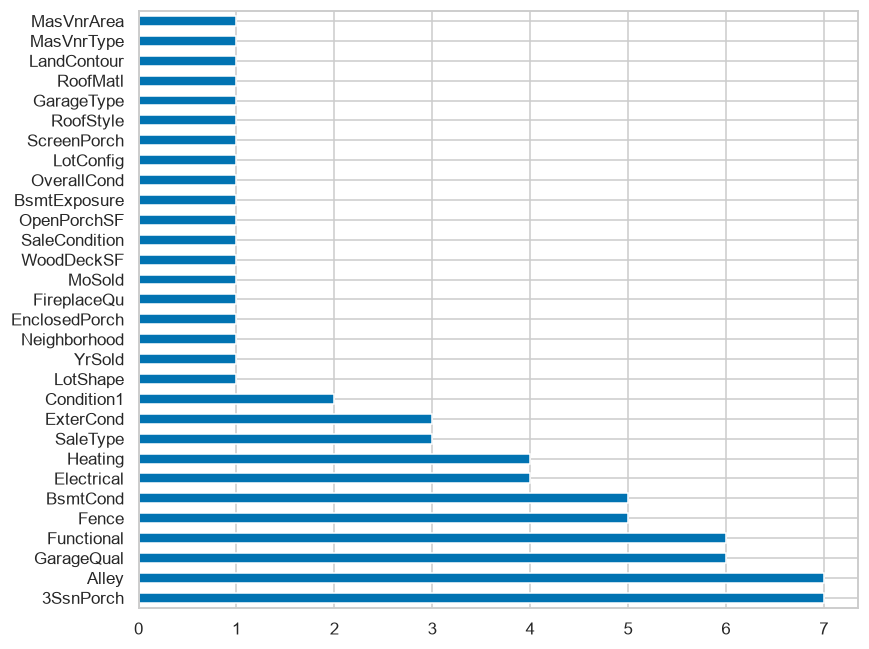

In [13]:
inicio = time.perf_counter()
selector_rfe = RFE(bosque(50, 10), n_features_to_select=k_wrapper, step=2).fit(X_pca_selected, y)
tiempo_rfe = time.perf_counter()-inicio
selected_features_rfe = np.array(selected_features_pca)[selector_rfe.get_support()].tolist()
X_rfe = selector_rfe.transform(X_pca_selected)
conjuntos['RFE'], matrices['RFE'] = selected_features_rfe, X_rfe
tiempos_seleccion['RFE'] = tiempo_rfe
ranking = pd.Series(selector_rfe.ranking_, index=selected_features_pca).sort_values()
print('Tiempo:', tiempo_rfe, '| features:', selected_features_rfe)
ranking.head(30).sort_values(ascending=False).plot.barh(figsize=(8, 6)); plt.tight_layout(); plt.show()

### Paso 4.4: Comparación de Features Seleccionadas (Todos los Wrapper Methods)

In [14]:
def consenso(diccionario):
    unicas = sorted(set().union(*map(set, diccionario.values())))
    return pd.Series({f:sum(f in fs for fs in diccionario.values()) for f in unicas}).sort_values(ascending=False)
metodos_cinco = {m:conjuntos[m] for m in ['F-test','MI','Forward','Backward','RFE']}
votos_cinco = consenso(metodos_cinco)
consistent_features = votos_cinco[votos_cinco == len(metodos_cinco)].index.tolist()
robust_features = votos_cinco[votos_cinco >= 2].index.tolist()
print('Consistentes en los cinco métodos:', consistent_features)
print('En al menos dos:', robust_features)
pd.Series(tiempos_seleccion, name='segundos')

Consistentes en los cinco métodos: ['GarageType', 'OpenPorchSF', 'Neighborhood']
En al menos dos: ['GarageType', 'OpenPorchSF', 'Neighborhood', 'FireplaceQu', 'RoofStyle', 'LotShape', 'BsmtExposure', 'Electrical', 'ScreenPorch', 'MasVnrType', 'MasVnrArea', 'OverallCond', 'SaleCondition', 'WoodDeckSF', 'BsmtFinSF1', 'CentralAir', 'GrLivArea', 'GarageYrBlt', 'GarageCars', 'Fireplaces', 'GarageArea', 'GarageFinish', 'Alley', '1stFlrSF', 'Condition2', 'Condition1', 'BsmtUnfSF', 'FullBath', 'ExterQual', 'Foundation', 'BsmtQual', '2ndFlrSF', 'TotalBsmtSF', 'RoofMatl', 'PoolQC', 'TotRmsAbvGrd', 'YearRemodAdd', 'YearBuilt', 'YrSold', 'OverallQual', 'LotFrontage', 'KitchenAbvGr', 'MSZoning', 'HeatingQC', 'LotArea', 'KitchenQual']


PCA Loadings     0.015568
F-test           0.004160
MI               0.315247
Forward         53.842789
Backward        70.771191
RFE              1.287490
Name: segundos, dtype: float64

### Pregunta Reflexiva 10 — Respuesta

F-test tardó 0.0042 s y MI 0.32 s; forward 53.8, backward 70.8 y RFE 1.29 s. Los wrappers entrenan modelos repetidamente, mientras los filtros calculan asociaciones. Los tres wrappers comparten 8 atributos: coincidencia parcial indica señal estable en algunos y sustitución entre correlacionados en otros. RFE elimina según importancia del modelo y requiere menos ajustes que buscar cada alternativa con CV. Forward es atractivo para una selección pequeña; backward para una grande; RFE como compromiso de costo. Ninguno garantiza el óptimo global.

### Paso 4.5: Evaluar Performance de Wrapper Methods

In [15]:
evaluaciones += [evaluar_matriz(m, matrices[m]) for m in ['Forward','Backward','RFE']]
comparison_updated_df = pd.DataFrame(evaluaciones)
comparison_updated_df['Reducción%'] = 100*(1-comparison_updated_df.N_Features/X.shape[1])
comparison_updated_df.sort_values('RMSE')

,Método,N_Features,RMSE,RMSE_std,R2,fit_s,Reducción%
4,MI,38,29839.934575,4485.556178,0.848327,0.517665,51.898734
0,Original,79,29930.880476,4497.706506,0.847647,0.712511,0.000000
3,F-test,38,30387.227780,4627.280747,0.842418,0.498289,51.898734
1,PCA 80%,38,31179.042836,3053.818354,0.836279,0.975310,51.898734
6,Backward,19,48757.677361,2473.166213,0.599238,0.266752,75.949367
5,Forward,19,49154.394358,2287.905191,0.591129,0.251540,75.949367
7,RFE,19,50076.953558,4230.722878,0.577457,0.321702,75.949367
2,PCA Loadings,38,50126.073898,4165.129384,0.576643,0.291164,51.898734


## Parte 5: Feature Selection - Embedded Methods

### Paso 5.1: Random Forest Feature Importance

Top 15: OverallQual     0.559586
GrLivArea       0.123686
TotalBsmtSF     0.035154
2ndFlrSF        0.031459
BsmtFinSF1      0.027284
1stFlrSF        0.027228
LotArea         0.017606
GarageArea      0.015178
GarageCars      0.014114
YearBuilt       0.013156
BsmtQual        0.008646
Neighborhood    0.008479
LotFrontage     0.007932
YearRemodAdd    0.007721
GarageFinish    0.006930


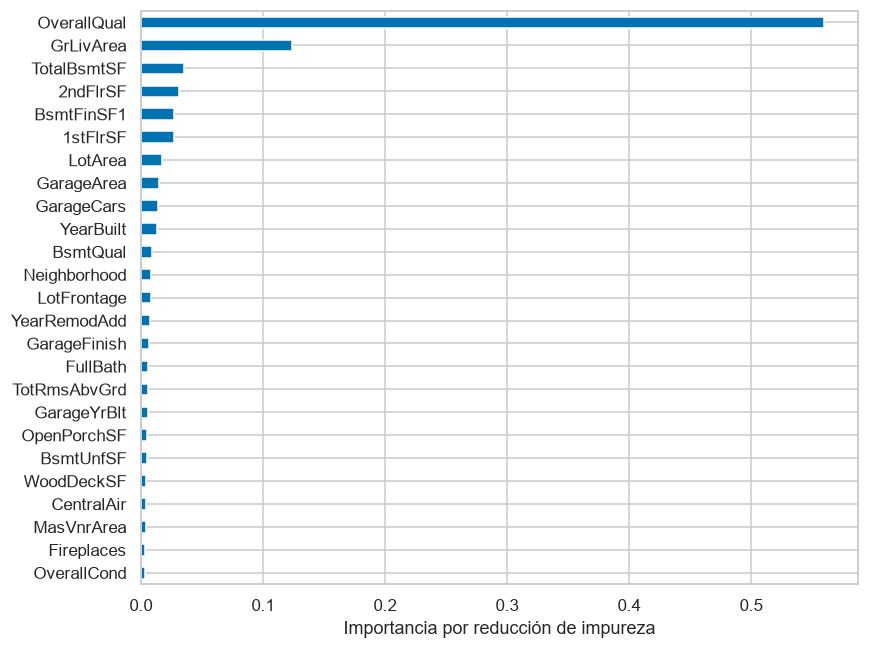

In [16]:
inicio = time.perf_counter()
rf_embedded = bosque(200, 10).fit(X_scaled, y)
importances = pd.Series(rf_embedded.feature_importances_, index=X.columns).sort_values(ascending=False)
top_k_features = importances.nlargest(k).index.tolist()
X_rf_importance = X_scaled[:, X.columns.get_indexer(top_k_features)]
conjuntos['RF Importance'], matrices['RF Importance'] = top_k_features, X_rf_importance
tiempos_seleccion['RF Importance'] = time.perf_counter()-inicio
evaluaciones.append(evaluar_matriz('RF Importance', X_rf_importance))
print('Top 15:', importances.head(15).to_string())
importances.head(25).sort_values().plot.barh(figsize=(8, 6)); plt.xlabel('Importancia por reducción de impureza'); plt.tight_layout(); plt.show()

### Pregunta Reflexiva 11 — Respuesta

El bosque prioriza OverallQual, GrLivArea, TotalBsmtSF, 2ndFlrSF, BsmtFinSF1; el consenso de varios métodos ayuda a identificar atributos estables, pero no equivale a importancia causal. RF mide aportes condicionados a splits e interacciones y puede repartir importancia entre atributos correlacionados; F-test y MI son univariados. La importancia por impureza también puede favorecer variables con muchas posibilidades de corte. Confiaría en la combinación de rendimiento independiente, estabilidad entre particiones y plausibilidad de negocio; contrastaría con importancia por permutación o SHAP antes de presentar explicaciones individuales.

### Paso 5.2: Lasso (L1 Regularization para Regresión)

Alpha: 988.7500698686109 | no cero: 50 / 79
Top: GrLivArea      22423.051954
OverallQual    15836.024045
PoolQC         14921.375331
PoolArea        9477.184858
BsmtQual        8493.469379
KitchenQual     7460.411807
ExterQual       6051.319445
GarageCars      6029.153883
YearBuilt       5958.358297
MSSubClass      5586.262480
BsmtFinSF1      4628.382045
OverallCond     4097.230892
LotArea         3663.430089
Fireplaces      3605.091751
Functional      3335.539269


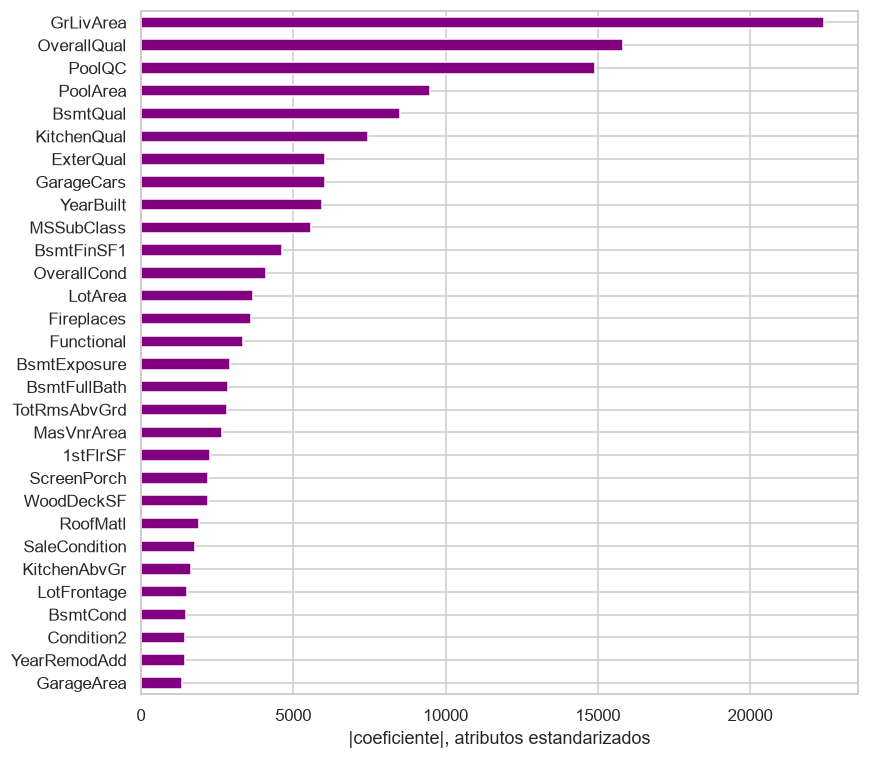

In [17]:
inicio = time.perf_counter()
lasso = LassoCV(cv=CV5, random_state=SEMILLA, max_iter=10000, n_jobs=N_JOBS).fit(X_scaled, y)
coef_abs = pd.Series(np.abs(lasso.coef_), index=X.columns).sort_values(ascending=False)
lasso_nonzero = X.columns[np.abs(lasso.coef_) > 1e-8].tolist()
lasso_features = coef_abs.nlargest(k).index.tolist()
X_lasso = X_scaled[:, X.columns.get_indexer(lasso_features)]
conjuntos['Lasso'], matrices['Lasso'] = lasso_features, X_lasso
tiempos_seleccion['Lasso'] = time.perf_counter()-inicio
evaluaciones.append(evaluar_matriz('Lasso', X_lasso))
print('Alpha:', lasso.alpha_, '| no cero:', len(lasso_nonzero), '/', X.shape[1])
print('Top:', coef_abs.head(15).to_string())
coef_abs.head(30).sort_values().plot.barh(figsize=(8, 7), color='purple'); plt.xlabel('|coeficiente|, atributos estandarizados'); plt.tight_layout(); plt.show()

### Pregunta Reflexiva — Lasso: Respuesta

Lasso dejó 29 coeficientes en cero y 50 activos, con alpha=988.75. Esto sugiere que muchas variables no aportan señal lineal adicional suficiente bajo esa penalización; no prueba que todas sean inútiles o redundantes para un modelo no lineal. Coincide con F-test en 24 de los 38 seleccionados. Sus coeficientes facilitan una explicación lineal, pero con atributos correlacionados puede elegir un sustituto y cambiar entre muestras. La selección por Lasso y la predicción por RF son dos etapas distintas; el ranking top-k podría incluir ceros si no hubiera k activos, por eso se informa también la cantidad de coeficientes no nulos.

## Parte 6: Comparación final de métodos

La página alude a esta parte en la pregunta 12 aunque omite su encabezado. Se completa aquí la tabla de todos los métodos.

In [18]:
comparison_final_df = pd.DataFrame(evaluaciones).sort_values('RMSE').reset_index(drop=True)
comparison_final_df['Reducción%'] = 100*(1-comparison_final_df.N_Features/X.shape[1])
comparison_final_df.to_csv('pca_resultados/comparacion_principal.csv', index=False)
comparison_final_df

,Método,N_Features,RMSE,RMSE_std,R2,fit_s,Reducción%
0,MI,38,29839.934575,4485.556178,0.848327,0.517665,51.898734
1,RF Importance,38,29908.624518,4292.351225,0.847856,0.650454,51.898734
2,Original,79,29930.880476,4497.706506,0.847647,0.712511,0.000000
3,F-test,38,30387.227780,4627.280747,0.842418,0.498289,51.898734
4,Lasso,38,30492.933942,4904.840381,0.842082,0.588456,51.898734
5,PCA 80%,38,31179.042836,3053.818354,0.836279,0.975310,51.898734
6,Backward,19,48757.677361,2473.166213,0.599238,0.266752,75.949367
7,Forward,19,49154.394358,2287.905191,0.591129,0.251540,75.949367
8,RFE,19,50076.953558,4230.722878,0.577457,0.321702,75.949367
9,PCA Loadings,38,50126.073898,4165.129384,0.576643,0.291164,51.898734


### Pregunta Reflexiva 12 — Respuesta

El menor RMSE exploratorio es de MI: $29,840, con 38 entradas. No lo recomendaría solo por ese mínimo: la selección previa puede sesgar CV, y hay que verificar error independiente, latencia y estabilidad. Feature selection permite hablar de atributos reales y diseñar formularios de tasación; PCA mezcla variables y requiere recolectar las originales para calcular cada componente.

Al CEO destacaría tres ideas: 1) la precisión se compara en dólares, 2) reducir entradas puede simplificar la captura y mantenimiento, 3) menor complejidad solo conviene si la pérdida de error es tolerable. Comunicaría cada reducción junto con RMSE, dispersión entre folds y costo medido. Los métodos que retienen variables facilitan la interpretación de las entradas, pero un Random Forest sigue necesitando herramientas de explicación del modelo; no confundir variables comprensibles con una regla de predicción sencilla.

## Parte 7: Investigación Libre (opcional)

Se resuelven las cuatro opciones, no solo una.

### Opción A: Forward/Backward Selection

In [19]:
opcion_a = pd.DataFrame([r for r in evaluaciones if r['Método'] in ['Forward','Backward','RFE']])
opcion_a['seleccion_s'] = opcion_a.Método.map(tiempos_seleccion)
opcion_a

,Método,N_Features,RMSE,RMSE_std,R2,fit_s,seleccion_s
0,Forward,19,49154.394358,2287.905191,0.591129,0.251540,53.842789
1,Backward,19,48757.677361,2473.166213,0.599238,0.266752,70.771191
2,RFE,19,50076.953558,4230.722878,0.577457,0.321702,1.287490


**Análisis A.** Se reutiliza la implementación completa de SFS forward y backward del apartado 4, y se contrasta con RFE. El menor RMSE de estos tres corresponde a Backward, mientras el menor costo de selección corresponde a RFE. Las estrategias recorren espacios diferentes; no se puede asumir que un wrapper más caro siempre gane.

### Opción B: SHAP Values para Feature Importance

OverallQual     29919.154554
GrLivArea       15448.617771
TotalBsmtSF      5881.727042
BsmtFinSF1       4032.189335
YearBuilt        2724.563456
GarageArea       2658.016365
1stFlrSF         2530.479867
LotArea          2013.127721
YearRemodAdd     1605.743257
GarageFinish     1540.581939
GarageCars       1478.496607
2ndFlrSF         1093.531377
CentralAir       1078.911484
Neighborhood      895.652696
Fireplaces        892.318164
Verificación aditividad, error máximo: 1.5133991837501526e-09


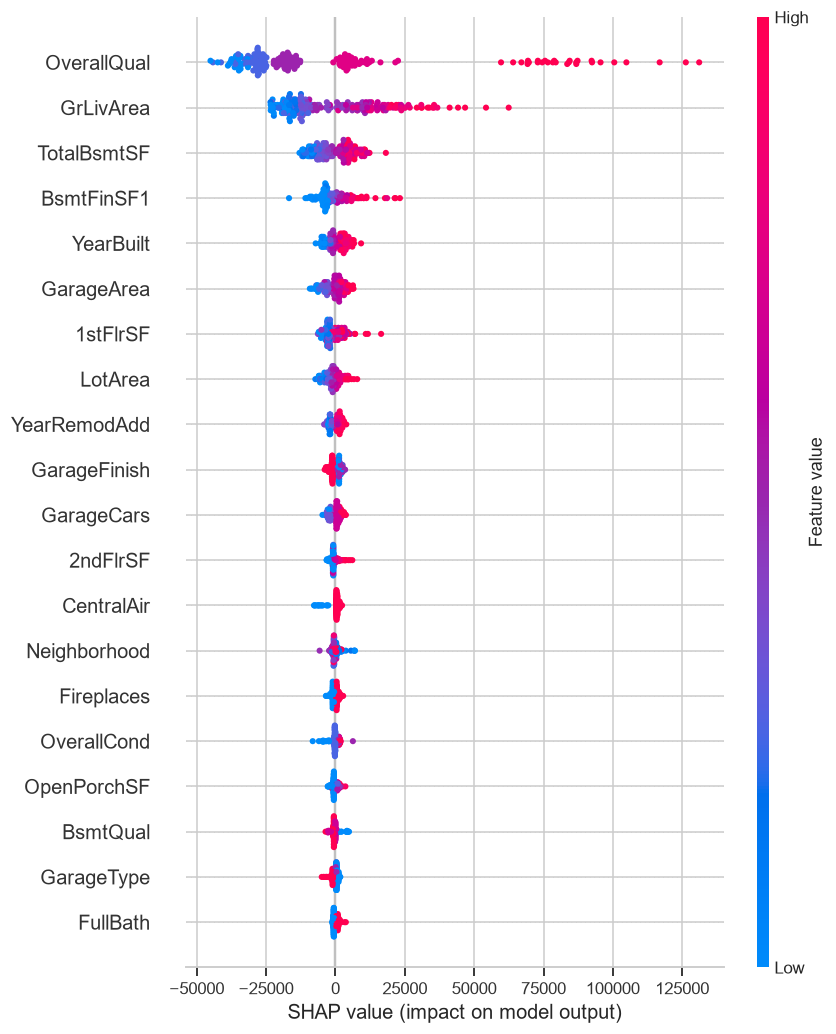

In [20]:
import shap
model_shap = bosque(100, 15).fit(X_scaled, y)
# Se explican 200 ejemplos de desarrollo; no se consulta la prueba para elegir variables.
indices_shap = np.random.default_rng(SEMILLA).choice(len(y), size=200, replace=False)
X_shap = X_scaled[indices_shap]
explainer = shap.TreeExplainer(model_shap)
shap_values = explainer.shap_values(X_shap)
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=X.columns).sort_values(ascending=False)
shap.summary_plot(shap_values, X_shap, feature_names=feature_names, max_display=20, show=False)
plt.tight_layout(); plt.show()
print(shap_importance.head(15).to_string())
print('Verificación aditividad, error máximo:', np.max(np.abs(
    shap_values.sum(axis=1)+np.asarray(explainer.expected_value).item()-model_shap.predict(X_shap))))

**Análisis B.** Los primeros cinco atributos por contribución SHAP absoluta media son OverallQual, GrLivArea, TotalBsmtSF, BsmtFinSF1, YearBuilt. Los valores indican contribuciones a la predicción, en dólares, respecto del valor base del modelo. El gráfico distingue la magnitud y dirección de aportes por casa, algo que la importancia global por impureza no muestra. Variables correlacionadas y la elección de cómo representar dependencias afectan la atribución; SHAP no transforma esas contribuciones en efectos causales ni asegura que el modelo sea correcto. Se explicaron 200 casas de desarrollo para acotar el costo.

### Opción C: PCA Incremental

In [21]:
ipca = IncrementalPCA(n_components=k, batch_size=256)
inicio = time.perf_counter()
ipca.fit(X_scaled)
tiempo_ipca = time.perf_counter()-inicio
X_ipca = ipca.transform(X_scaled)
recon_ipca = ipca.inverse_transform(X_ipca)
pca_k = PCA(n_components=k, svd_solver='full').fit(X_scaled)
recon_pca = pca_k.inverse_transform(pca_k.transform(X_scaled))
error_recon_ipca = np.mean((X_scaled-recon_ipca)**2)
error_recon_pca = np.mean((X_scaled-recon_pca)**2)
print('Varianza IPCA:', ipca.explained_variance_ratio_.sum(), '| tiempo:', tiempo_ipca)
print('MSE reconstrucción PCA:', error_recon_pca, '| IPCA:', error_recon_ipca)

Varianza IPCA: 0.7936803055885099 | tiempo: 0.007021500001428649
MSE reconstrucción PCA: 0.19400870390632186 | IPCA: 0.19949129770417723


**Análisis C.** IncrementalPCA procesa mini-batches de 256 ejemplos y conserva 38 componentes. Captura 79.37% de varianza; su MSE de reconstrucción estandarizada es 0.19949, frente a 0.19401 del PCA completo. IPCA aproxima el subespacio y puede perder algo de calidad respecto de la solución completa. Aquí los datos caben en memoria: el beneficio es ilustrar el algoritmo. Para datos realmente grandes se leerían los bloques desde disco y se estimaría el escalado con `partial_fit` antes de alimentar IPCA; además, cada batch debe permitir estimar el número solicitado de componentes. No se compara componente a componente sin considerar signos y posibles rotaciones.

### Opción D: Feature Engineering + Selection

In [22]:
poly = PolynomialFeatures(degree=2, include_bias=False, interaction_only=True)
X_interactions = poly.fit_transform(X_scaled)
interaction_names = poly.get_feature_names_out(feature_names)
selector_inter = SelectKBest(f_regression, k=k).fit(X_interactions, y)
features_inter = interaction_names[selector_inter.get_support()].tolist()
X_inter_selected = selector_inter.transform(X_interactions)
eval_inter = evaluar_matriz('Interacciones + F-test', X_inter_selected)
print('Expansión:', X.shape[1], '->', X_interactions.shape[1], '->', k)
print('Seleccionadas:', features_inter)
print(eval_inter)

Expansión: 79 -> 3160 -> 38
Seleccionadas: ['OverallQual', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'TotalBsmtSF', '1stFlrSF', 'GrLivArea', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'ExterQual', 'BsmtQual', 'HeatingQC', 'KitchenQual', 'GarageFinish', 'OverallQual ExterQual', 'OverallQual BsmtQual', 'OverallQual KitchenQual', 'YearBuilt BsmtQual', 'MasVnrArea ExterQual', 'MasVnrArea BsmtQual', 'GrLivArea KitchenQual', 'TotRmsAbvGrd KitchenQual', 'GarageYrBlt ExterQual', 'GarageYrBlt BsmtQual', 'GarageCars ExterQual', 'GarageCars BsmtQual', 'GarageCars KitchenQual', 'GarageArea ExterQual', 'GarageArea BsmtQual', 'GarageArea KitchenQual', 'ExterQual BsmtQual', 'ExterQual KitchenQual', 'BsmtQual KitchenQual', 'KitchenQual GarageFinish']
{'Método': 'Interacciones + F-test', 'N_Features': 38, 'RMSE': np.float64(33812.487479090705), 'RMSE_std': np.float64(4748.246554921901), 'R2': np.float64(0.8053058268701259), 'fit_s': np.float64(0.72088837623596

**Análisis D.** La expansión genera 3160 columnas y se retienen 38. El RMSE exploratorio es $33,812, frente a $29,931 del bosque original. El bosque ya puede aprender interacciones; añadir productos no garantiza mejorar. Los productos de códigos nominales tienen una interpretación frágil, porque dependen del orden alfabético impuesto. Para producción diseñaría interacciones justificadas de variables numéricas o usaría una codificación nominal adecuada y repetiría la selección dentro de validación. La comparación es exploratoria: no se interpreta su mínimo como una estimación independiente.

## Reflexión Final Integradora (OBLIGATORIO)

### A. Sobre PCA

**1. Interpretabilidad.** PC1 resume covariación de OverallQual, YearBuilt, GarageCars, GarageArea. Puede ser útil como resumen visual, pero para un agente es más práctico hablar de los atributos originales y de sus valores observables.

**2. Varianza explicada.** Si PC1 explicara 40 %, significaría que 40 % de la suma de varianzas de los atributos usados queda en ese eje. No significa explicar 40 % del precio ni acertar 40 % de las casas. El 60 % restante está en otros componentes y solo se pierde si se descartan; puede contener señal predictiva relevante. Aquí PC1 explica 13.10%, no se impone el 40 % del ejemplo.

**3. Tres usos fuera de este dataset.** Compresión de espectros de sensores con canales correlacionados; representación compacta de imágenes para almacenamiento o reconocimiento; visualización de perfiles genómicos con miles de mediciones correlacionadas. En esos casos puede interesar preservar un subespacio global sin conservar nombres individuales.

**4. Limitación inmobiliaria.** Mezclar atributos dificulta explicar una tasación y no elimina la necesidad de recolectarlos. Además, maximizar varianza de X no maximiza utilidad predictiva para SalePrice.

### B. Sobre Feature Selection

**1. Consistencia.** Compararía error independiente, estabilidad entre folds y costo de capturar cada conjunto. Un consenso sirve para proponer candidatos, no para reemplazar validación; se puede rankear por frecuencia de selección y validar varios tamaños.

**2. GarageArea y GarageCars.** Su correlación en desarrollo es 0.883. Mantendría el atributo más estable, barato y confiable en la captura, comprobando el cambio de error al retirar el otro. La correlación no dice automáticamente cuál es prescindible y podrían aportar información adicional condicionada al resto.

**3. Filter vs Wrapper.** F-test calcula una asociación por atributo; RFE vuelve a entrenar después de retirar variables. El costo extra se justifica si una mejora validada o una reducción operacional relevante compensa el tiempo. RFE no garantiza superar un filtro y puede ser inestable entre atributos correlacionados.

**4. Lasso Shrinkage.** Si 40 coeficientes quedaran en cero, indicaría que bajo ese alpha esas variables no aportan suficiente señal lineal adicional para compensar la penalización. No prueba inutilidad para todos los modelos. En esta ejecución quedan 29 en cero. Tanto la escala como las correlaciones y el valor de alpha influyen en la selección.

## Trabajos Domiciliarios (Opcionales pero Recomendados)

Se completan los tres. Cada trabajo tiene un bloque compacto de resultados y análisis; el detalle reproducible queda en sus celdas de código.

### Trabajo Domiciliario 1: Comparación de Umbrales de Varianza en PCA

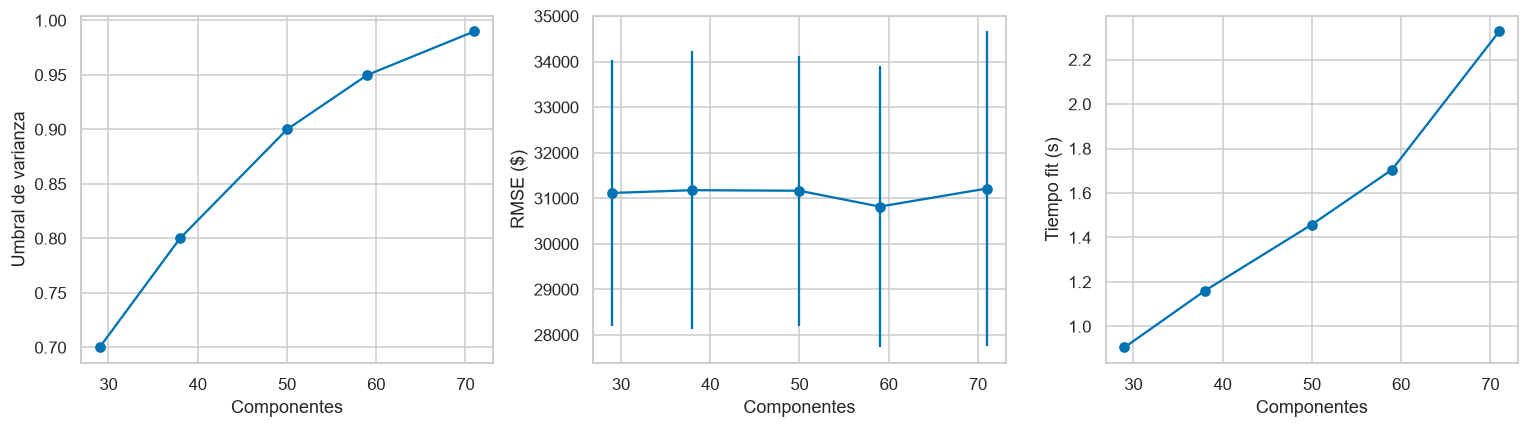

,umbral,n_componentes,RMSE,RMSE_std,R2,fit_total_s,infer_100_ms
0,0.70,29,31117.605548,2919.942474,0.836499,0.905441,13.64270
1,0.80,38,31179.042836,3053.818354,0.836279,1.160139,13.83405
2,0.90,50,31166.551808,2961.126892,0.836383,1.458352,11.47655
3,0.95,59,30818.686932,3092.553299,0.840212,1.705588,12.96755
4,0.99,71,31215.541196,3450.317121,0.835820,2.327186,18.95970


In [23]:
umbrales = [0.70, 0.80, 0.90, 0.95, 0.99]
registros_umbrales = []
for u in umbrales:
    resultado = evaluar_pca(u)
    pipe = make_pipeline(make_preprocessor(), StandardScaler(), PCA(n_components=u, svd_solver='full'), bosque())
    inicio = time.perf_counter(); pipe.fit(X_dev_raw, y); fit_total = time.perf_counter()-inicio
    # Predicción de un batch de desarrollo: no usa los precios de prueba.
    batch = X_dev_raw.iloc[:100]
    pipe.predict(batch)  # calentamiento
    medidas = []
    for _ in range(20):
        inicio = time.perf_counter(); pipe.predict(batch); medidas.append(time.perf_counter()-inicio)
    registros_umbrales.append({**resultado, 'umbral':u, 'n_componentes':pipe[-2].n_components_,
                               'fit_total_s':fit_total, 'infer_100_ms':1000*np.median(medidas)})
tabla_umbrales = pd.DataFrame(registros_umbrales)
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
axs[0].plot(tabla_umbrales.n_componentes, tabla_umbrales.umbral, 'o-')
axs[0].set(xlabel='Componentes', ylabel='Umbral de varianza')
axs[1].errorbar(tabla_umbrales.n_componentes, tabla_umbrales.RMSE, yerr=tabla_umbrales.RMSE_std, fmt='o-')
axs[1].set(xlabel='Componentes', ylabel='RMSE ($)')
axs[2].plot(tabla_umbrales.n_componentes, tabla_umbrales.fit_total_s, 'o-')
axs[2].set(xlabel='Componentes', ylabel='Tiempo fit (s)')
plt.tight_layout(); plt.show()
tabla_umbrales.to_csv('pca_resultados/umbrales_pca.csv', index=False)
tabla_umbrales[['umbral','n_componentes','RMSE','RMSE_std','R2','fit_total_s','infer_100_ms']]

**Análisis del trabajo 1.** El menor RMSE se alcanza con umbral 95% y 59 componentes. La curva y las barras de dispersión muestran si aumentar dimensionalidad aporta una mejora apreciable; no hay que inventar un codo ni tratar un desvío entre folds como un test formal de significación. Más varianza conservada puede reducir pérdida predictiva, pero un bosque no aprovecha necesariamente todos los ejes de la misma manera.

La inferencia de 100 casas con 70 % demora 13.64 ms y con 99 % 18.96 ms: diferencia 5.32 ms por batch, con signo positivo si 70 % ahorra tiempo. Esta medición incluye preprocesamiento y no equivale a latencia en un teléfono. Para móvil ensayaría el umbral más bajo cuyo error sea tolerable para negocio, y lo mediría en el dispositivo; aquí la tabla permite identificar esa región sin asumir que 70 % sea siempre mejor.

En estos datos no aparece un codo claro: de 29 a 71 componentes, el RMSE se mantiene entre $30,819 y $31,216, un rango de $397, pequeño frente a la dispersión por fold. No se observa una mejora consistente al superar los 29 componentes de 70 %; 95 % da el mínimo puntual, pero 99 % vuelve a subir. Para una primera prueba en móvil propondría 70 % (29 componentes), validando que su error sea aceptable y midiendo el dispositivo. Aquí el ahorro medido frente a 99 % fue 28.0 % por batch; no se atribuye todo el ahorro exclusivamente a la cantidad de componentes, porque también hay variabilidad de medición.

### Trabajo Domiciliario 2: Feature Selection - Comparación de Métodos Filter

F-test : ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'ExterQual', 'BsmtQual', 'TotalBsmtSF', 'KitchenQual', '1stFlrSF', 'FullBath', 'GarageFinish', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt']
MI : ['OverallQual', 'Neighborhood', 'GrLivArea', 'GarageArea', 'GarageCars', 'TotalBsmtSF', 'YearBuilt', 'BsmtQual', 'KitchenQual', 'ExterQual', '1stFlrSF', 'MSSubClass', 'GarageYrBlt', 'FullBath', 'GarageFinish']
Pearson : ['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'ExterQual', 'BsmtQual', 'TotalBsmtSF', 'KitchenQual', '1stFlrSF', 'FullBath', 'GarageFinish', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd', 'GarageYrBlt']
Chi2 : ['GrLivArea', 'YearBuilt', 'GarageArea', 'TotalBsmtSF', '1stFlrSF', 'YearRemodAdd', 'GarageYrBlt', 'OverallQual', 'LotArea', 'OpenPorchSF', 'TotRmsAbvGrd', 'MasVnrArea', 'WoodDeckSF', 'Fireplaces', '2ndFlrSF']
Robustas en los cuatro: ['1stFlrSF', 'GarageArea', 'YearBuilt', 'OverallQual', 'TotalBsmtSF', 'GarageYrBlt', 'GrLivArea']
Con

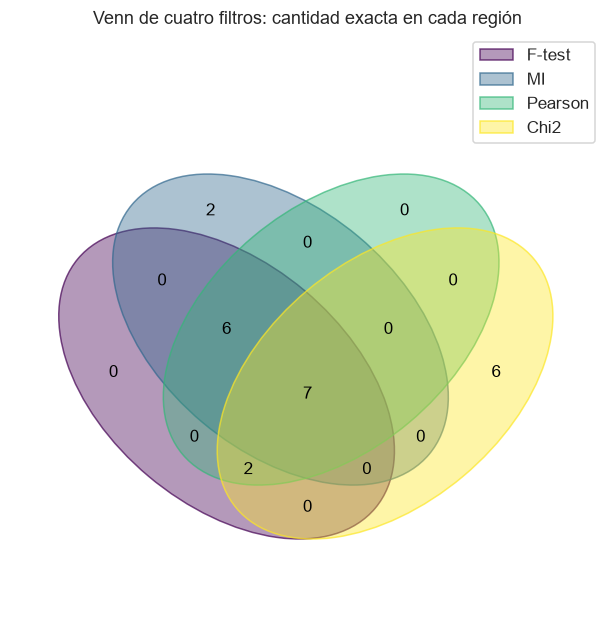

,Método,N_Features,RMSE,RMSE_std,R2,fit_s
1,MI,15,32057.983916,4800.067669,0.823370,0.351685
3,Chi2,15,32353.312103,3976.731726,0.822365,0.423907
0,F-test,15,32977.350097,5347.896704,0.812604,0.354401
2,Pearson,15,32977.350097,5347.896704,0.812604,0.361452


In [24]:
K_DOM = 15
pearson_scores = X.apply(lambda col: abs(col.corr(y))).fillna(0).sort_values(ascending=False)
# chi2 requiere un target de clasificación; se agrupan precios en quintiles.
# Los predictores se discretizan en bins no negativos. No se aplica chi2 al precio continuo.
bins = KBinsDiscretizer(n_bins=5, strategy='quantile', encode='ordinal', subsample=None,
                        quantile_method='averaged_inverted_cdf')
X_bins = bins.fit_transform(X_scaled)
y_bins = pd.qcut(y, q=5, labels=False, duplicates='drop')
chi_scores = pd.Series(chi2(X_bins, y_bins)[0], index=X.columns).fillna(0).sort_values(ascending=False)
filters_dom = {'F-test':f_scores.nlargest(K_DOM).index.tolist(),
               'MI':mi_scores.nlargest(K_DOM).index.tolist(),
               'Pearson':pearson_scores.nlargest(K_DOM).index.tolist(),
               'Chi2':chi_scores.nlargest(K_DOM).index.tolist()}
eval_filters_dom = []
for nombre, nombres in filters_dom.items():
    print(nombre, ':', nombres)
    eval_filters_dom.append(evaluar_matriz(nombre, X_scaled[:, X.columns.get_indexer(nombres)]))
tabla_filters_dom = pd.DataFrame(eval_filters_dom).sort_values('RMSE')
votos_filter_dom = consenso(filters_dom)
print('Robustas en los cuatro:', votos_filter_dom[votos_filter_dom==4].index.tolist())
print('Controversiales (uno o dos):', votos_filter_dom[votos_filter_dom<=2].index.tolist())
# Venn de cuatro conjuntos con todas sus regiones etiquetadas.
from venn import venn
fig, ax = plt.subplots(figsize=(9, 7))
venn({nombre:set(fs) for nombre,fs in filters_dom.items()}, ax=ax,
     fontsize=11, legend_loc='upper right')
ax.set_title('Venn de cuatro filtros: cantidad exacta en cada región')
plt.show()
patrones = {}
for f in votos_filter_dom.index:
    patron = ' & '.join(n for n, fs in filters_dom.items() if f in fs)
    patrones.setdefault(patron, []).append(f)
tabla_venn = pd.DataFrame([{'Región exacta':p,'Cantidad':len(fs),
                           'Features':', '.join(fs)} for p,fs in patrones.items()])
print(tabla_venn.to_string(index=False))
tabla_filters_dom

**Análisis del trabajo 2.** F-test y Pearson comparten 15 de 15 variables. Para el mismo conjunto sin nulos, `f_regression` es una transformación monótona de la correlación de Pearson al cuadrado: se espera el mismo ranking salvo empates o diferencias de implementación. La premisa de que necesariamente eligen variables diferentes es incorrecta.

El mejor RMSE exploratorio es MI ($32,058). Coinciden los cuatro filtros en 1stFlrSF, GarageArea, YearBuilt, OverallQual, TotalBsmtSF, GarageYrBlt, GrLivArea. Las discrepancias pueden reflejar dependencia no lineal, discretización y ruido. Chi2 evalúa asociación con grupos de precios, no regresión directa; pierde información del target continuo. Un ensemble posible rankea por frecuencia de selección o suma de rankings normalizados y valida el tamaño del subconjunto; no elegiría solo por votos si una variable esencial para negocio fuera inestable. El Venn etiqueta todas las regiones con sus conteos exactos; las áreas dibujadas no son proporcionales al número de variables. La tabla permite identificar cuáles son esas variables.

### Trabajo Domiciliario 3: Wrapper Methods - Sequential Feature Selection

In [25]:
# Este trabajo usa los 79 atributos originales como candidatos, no la preselección PCA.
selector_fd, features_fd, X_fd, tiempo_fd = ejecutar_wrapper('forward', X_scaled, feature_names, K_DOM, 'dom_forward')
selector_bd, features_bd, X_bd, tiempo_bd = ejecutar_wrapper('backward', X_scaled, feature_names, K_DOM, 'dom_backward')
inicio = time.perf_counter()
rfe_dom = RFE(bosque(50,10), n_features_to_select=K_DOM, step=2).fit(X_scaled, y)
tiempo_rfe_dom = time.perf_counter()-inicio
features_rd = X.columns[rfe_dom.get_support()].tolist()

# Búsqueda bidireccional: forward seguido por intercambios add/remove
# que mejoran RMSE interno. Cada intercambio mantiene exactamente 15 variables.
# Los candidatos de cada ronda se evalúan en paralelo sin anidar RF paralelo.
from sklearn.utils.parallel import Parallel, delayed
def puntuar_subconjunto(indices):
    Z = X_scaled[:, indices]
    return float(-cross_val_score(bosque(50,10), Z, y, cv=CV3,
                                 scoring='neg_root_mean_squared_error', n_jobs=1).mean())
inicio = time.perf_counter()
base_bi = sorted(X.columns.get_indexer(features_fd).tolist())
score_bi = puntuar_subconjunto(base_bi)
mejoras_bi = []
for ronda in range(3):
    fuera = sorted(set(range(X.shape[1]))-set(base_bi))
    # Primero incorporar el mejor candidato y luego eliminar el peor
    agregados = [sorted(base_bi+[j]) for j in fuera]
    with parallel_backend('threading'):
        scores = Parallel(n_jobs=N_JOBS)(delayed(puntuar_subconjunto)(s) for s in agregados)
    ampliado = agregados[int(np.argmin(scores))]
    reducidos = [[j for j in ampliado if j!=i] for i in ampliado]
    with parallel_backend('threading'):
        scores_r = Parallel(n_jobs=N_JOBS)(delayed(puntuar_subconjunto)(s) for s in reducidos)
    candidato, nuevo = reducidos[int(np.argmin(scores_r))], min(scores_r)
    if nuevo >= score_bi-1e-6:
        break
    mejoras_bi.append({'ronda':ronda+1,'rmse_antes':score_bi,'rmse_después':nuevo})
    base_bi, score_bi = candidato, nuevo
tiempo_bi_refinar = time.perf_counter()-inicio
features_bi = X.columns[base_bi].tolist()

# Early stopping: detener luego de tres tamaños sin mejorar el mejor RMSE.
# Se mide desde cero y se retiene el subconjunto de la mejor iteración.
inicio = time.perf_counter()
seleccion_es, mejor_es, historial_es = [], [], []
best_es, paciencia = np.inf, 0
for tam in range(1, X.shape[1]):
    candidatos = [sorted(seleccion_es+[j]) for j in range(X.shape[1]) if j not in seleccion_es]
    with parallel_backend('threading'):
        valores = Parallel(n_jobs=N_JOBS)(delayed(puntuar_subconjunto)(s) for s in candidatos)
    pos = int(np.argmin(valores)); seleccion_es, valor = candidatos[pos], valores[pos]
    historial_es.append({'n_features':tam, 'RMSE_CV3':valor})
    if valor < best_es-1e-6:
        best_es, mejor_es, paciencia = valor, seleccion_es.copy(), 0
    else:
        paciencia += 1
    if paciencia == 3:
        break
tiempo_es = time.perf_counter()-inicio
features_es = X.columns[mejor_es].tolist()
wrappers_dom = {'RFE':features_rd,'Forward':features_fd,'Backward':features_bd,
                'Bidireccional':features_bi,'Forward Early Stopping':features_es}
duraciones_dom = {'RFE':tiempo_rfe_dom,'Forward':tiempo_fd,'Backward':tiempo_bd,
                  'Bidireccional':tiempo_fd+tiempo_bi_refinar,'Forward Early Stopping':tiempo_es}
eval_wrappers_dom = []
for nombre,nombres in wrappers_dom.items():
    print(nombre, ':', nombres)
    eval_wrappers_dom.append(evaluar_matriz(nombre, X_scaled[:, X.columns.get_indexer(nombres)]))
tabla_wrappers_dom = pd.DataFrame(eval_wrappers_dom)
tabla_wrappers_dom['seleccion_s'] = tabla_wrappers_dom.Método.map(duraciones_dom)
overlap_dom = pd.DataFrame({a:{b:len(set(fa)&set(fb)) for b,fb in wrappers_dom.items()}
                            for a,fa in wrappers_dom.items()})
print('Coincidencias absolutas:'); print(overlap_dom.to_string())
print('Mejoras bidireccionales:', mejoras_bi)
print('Early stopping: tamaños probados:', len(historial_es), '| tamaño retenido:', len(features_es))
tabla_wrappers_dom.to_csv('pca_resultados/wrappers_completos.csv',index=False)
tabla_wrappers_dom.sort_values('RMSE')

RFE : ['LotFrontage', 'LotArea', 'OverallQual', 'YearBuilt', 'YearRemodAdd', 'BsmtFinSF1', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'GrLivArea', 'GarageCars', 'GarageArea', 'Neighborhood', 'BsmtQual', 'GarageFinish']
Forward : ['LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'BsmtFinSF1', 'TotalBsmtSF', 'GrLivArea', 'FullBath', 'GarageCars', 'ScreenPorch', 'MSZoning', 'Neighborhood', 'KitchenQual', 'GarageType', 'SaleType']
Backward : ['MSSubClass', 'OverallCond', 'YearBuilt', 'BsmtFinSF1', 'GrLivArea', 'BedroomAbvGr', 'Fireplaces', 'GarageCars', 'ScreenPorch', 'MSZoning', 'LandSlope', 'Neighborhood', 'ExterQual', 'KitchenQual', 'Functional']
Bidireccional : ['LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'BsmtFinSF1', 'TotalBsmtSF', '2ndFlrSF', 'GrLivArea', 'GarageCars', 'ScreenPorch', 'MSZoning', 'Neighborhood', 'KitchenQual', 'GarageType', 'SaleType']
Forward Early Stopping : ['LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'BsmtFinSF1', 'TotalBsmtSF', '2ndFlrSF', '

,Método,N_Features,RMSE,RMSE_std,R2,fit_s,seleccion_s
4,Forward Early Stopping,20,28978.357763,4346.036848,0.856465,0.375170,160.163647
3,Bidireccional,15,29101.417336,4416.644237,0.855566,0.347626,163.035816
1,Forward,15,29824.839841,5646.678647,0.846057,0.346375,146.669490
0,RFE,15,29962.725112,4384.607534,0.846406,0.412128,9.145256
2,Backward,15,30441.849147,7128.785915,0.838223,0.301865,700.566476


**Análisis del trabajo 3.** El método más rápido fue RFE, con 9.15 s; el mejor RMSE exploratorio fue Forward Early Stopping, $28,978. El trabajo parte de las 79 variables: forward añade desde cero, backward elimina desde todas y RFE descarta por importancia. Sus caminos no tienen por qué converger al mismo conjunto; la matriz informa el solapamiento exacto.

La implementación bidireccional usa el forward completo como punto de partida y permite hasta tres rondas de incorporación y eliminación mientras mejora CV3; el tiempo incluye construir esa base. No se presenta como un algoritmo disponible con `direction='both'` en sklearn: esa opción no existe en SequentialFeatureSelector. El early stopping exploró 23 tamaños, retuvo 20 atributos y demoró 160.2 s frente a 146.7 s del forward fijo de 15. Puede no ahorrar tiempo si el RMSE sigue mejorando durante muchas etapas. La comparación también cambia el tamaño final, y debe interpretarse así.

El costo extra respecto de F-test solo se justifica con mejoras independientes y útiles o reducción del costo de captura. Usaría wrappers con presupuesto disponible, pocos candidatos y un modelo estable; con miles de variables empezaría por filtros. Se puede acelerar con preselección, menos folds, árboles más chicos durante búsqueda, evaluación paralela de candidatos y caché; después confirmaría la elección con un modelo final y evaluación independiente. La CV condicionada a selecciones completas tiende a ser optimista.

## Auditoría metodológica: selección dentro de cada fold y prueba final

In [26]:
# Auditoría fold-safe de filtros rápidos: todo se ajusta en el fold de train.
auditoria = []
for nombre, selector in [('Original', 'passthrough'), ('F-test', SelectKBest(f_regression,k=k)),
                          ('MI', SelectKBest(lambda Z,t: mutual_info_regression(Z,t,random_state=SEMILLA),k=k)),
                          ('RF Importance', RFE(bosque(50,10),n_features_to_select=k,step=10))]:
    pipe = Pipeline([('pre',make_preprocessor()),('scaler',StandardScaler()),
                     ('seleccion',selector),('modelo',bosque())])
    with parallel_backend('threading'):
        r = cross_validate(pipe,X_dev_raw,y,cv=CV5,
                           scoring={'rmse':'neg_root_mean_squared_error','r2':'r2'},n_jobs=N_JOBS)
    auditoria.append({'Método':nombre,'RMSE':-r['test_rmse'].mean(),
                      'RMSE_std':r['test_rmse'].std(),'R2':r['test_r2'].mean()})
# La fila RFE es una auditoría embedded aproximada; no se confunde con top-k de un único RF.
auditoria[-1]['Método'] = 'RFE fold-safe'
auditoria_df = pd.DataFrame(auditoria).sort_values('RMSE')
print(auditoria_df.to_string(index=False))
ganador_auditado = auditoria_df.iloc[0]['Método']
selector_final = {'Original':'passthrough','F-test':SelectKBest(f_regression,k=k),
                  'MI':SelectKBest(lambda Z,t: mutual_info_regression(Z,t,random_state=SEMILLA),k=k),
                  'RFE fold-safe':RFE(bosque(50,10),n_features_to_select=k,step=10)}[ganador_auditado]
# Fijar método antes de consultar y_test. No se comparan candidatos sobre prueba.
modelo_final = Pipeline([('pre',make_preprocessor()),('scaler',StandardScaler()),
                         ('seleccion',selector_final),('modelo',bosque())]).fit(X_dev_raw,y)
pred_test = modelo_final.predict(X_test_raw)
rmse_test = np.sqrt(mean_squared_error(y_test,pred_test))
r2_test = r2_score(y_test,pred_test)
print('Método fijado:', ganador_auditado,'| prueba final RMSE:',rmse_test,'| R²:',r2_test)
print('Prueba:',len(y_test),'casas, nunca usadas en selección ni preprocesamiento.')
pd.DataFrame({'Id':df.loc[X_test_raw.index,'Id'],'SalePrice_real':y_test,
              'SalePrice_predicho':pred_test}).to_csv('pca_resultados/prueba_final.csv',index=False)

       Método         RMSE    RMSE_std       R2
     Original 29948.382584 4406.238754 0.847584
           MI 30114.917171 4570.304019 0.845221
RFE fold-safe 30121.993344 4419.572468 0.845709
       F-test 30292.788023 4188.207588 0.843643
Método fijado: Original | prueba final RMSE: 28475.646887614665 | R²: 0.8942857912733441
Prueba: 292 casas, nunca usadas en selección ni preprocesamiento.


**Conclusión de evaluación.** Entre los cuatro candidatos auditados, se fijó Original con RMSE CV de $29,948; luego, una sola consulta a las 292 casas reservadas produjo RMSE $28,476 y R²=0.894. Es el resultado independiente a reportar para ese modelo. La auditoría no demuestra que sea el mejor de todos los wrappers caros: solo compara los cuatro pipelines definidos. Las tablas anteriores cumplen el análisis exploratorio de la actividad, y sus mínimos no deben comunicarse como errores independientes. Una evaluación de producción también verificaría generalización temporal o a barrios nuevos, drift y costo real de captura.

## Recursos y reproducibilidad

- [Consigna UT3-10](https://juanfkurucz.com/ucu-id/ut3/10-pca-feature-selection/).
- [Dataset original de Kaggle](https://www.kaggle.com/c/house-prices-advanced-regression-techniques).
- [Copia pública de train.csv usada en esta ejecución](https://d2l-data.s3-accelerate.amazonaws.com/kaggle_house_pred_train.csv).
- [Documentación PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).
- [Feature selection en scikit-learn](https://scikit-learn.org/stable/modules/feature_selection.html).
- [SHAP TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).

In [27]:
import sys, sklearn, shap
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__, '| SHAP:', shap.__version__)

Python: 3.12.10
NumPy: 2.5.3 | pandas: 3.0.6 | sklearn: 1.9.1 | SHAP: 0.53.0


## Reflexión final integradora — cierre de la entrega

**1. Interpretabilidad.** PC1 resume covariación de OverallQual, YearBuilt, GarageCars, GarageArea. Puede ser útil como resumen visual, pero para un agente es más práctico hablar de los atributos originales y de sus valores observables.

**2. Varianza explicada.** Si PC1 explicara 40 %, significaría que 40 % de la suma de varianzas de los atributos usados queda en ese eje. No significa explicar 40 % del precio ni acertar 40 % de las casas. El 60 % restante está en otros componentes y solo se pierde si se descartan; puede contener señal predictiva relevante. Aquí PC1 explica 13.10%, no se impone el 40 % del ejemplo.

**3. Tres usos fuera de este dataset.** Compresión de espectros de sensores con canales correlacionados; representación compacta de imágenes para almacenamiento o reconocimiento; visualización de perfiles genómicos con miles de mediciones correlacionadas. En esos casos puede interesar preservar un subespacio global sin conservar nombres individuales.

**4. Limitación inmobiliaria.** Mezclar atributos dificulta explicar una tasación y no elimina la necesidad de recolectarlos. Además, maximizar varianza de X no maximiza utilidad predictiva para SalePrice.

**1. Consistencia.** Compararía error independiente, estabilidad entre folds y costo de capturar cada conjunto. Un consenso sirve para proponer candidatos, no para reemplazar validación; se puede rankear por frecuencia de selección y validar varios tamaños.

**2. GarageArea y GarageCars.** Su correlación en desarrollo es 0.883. Mantendría el atributo más estable, barato y confiable en la captura, comprobando el cambio de error al retirar el otro. La correlación no dice automáticamente cuál es prescindible y podrían aportar información adicional condicionada al resto.

**3. Filter vs Wrapper.** F-test calcula una asociación por atributo; RFE vuelve a entrenar después de retirar variables. El costo extra se justifica si una mejora validada o una reducción operacional relevante compensa el tiempo. RFE no garantiza superar un filtro y puede ser inestable entre atributos correlacionados.

**4. Lasso Shrinkage.** Si 40 coeficientes quedaran en cero, indicaría que bajo ese alpha esas variables no aportan suficiente señal lineal adicional para compensar la penalización. No prueba inutilidad para todos los modelos. En esta ejecución quedan 29 en cero. Tanto la escala como las correlaciones y el valor de alpha influyen en la selección.